# Modelo de Grau Nublado (Fuzzy)

In [1]:
caminho_do_arquivo = '/media/juan/SSD_D/ufc/2026.2/instrumentação/Projeto_grupo_4/Projeto/eplusout.csv'

In [49]:
import os
import numpy as np
import matplotlib.pyplot as plt

In [4]:
import pandas as pd
from scipy.stats import qmc

In [5]:
!pip install -U scikit-fuzzy matplotlib
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [25]:
%pip install networkx

Note: you may need to restart the kernel to use updated packages.


In [6]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [45]:
pip install scikit-fuzzy

Note: you may need to restart the kernel to use updated packages.


### Definição do LHS Hipercubo Latino

In [9]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [10]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


Aplicação usando um parametro genérico de exemplo

In [46]:
limites_parametros = {
    'temp_setpoint': [18.0, 26.0],       # Ex: Temperatura (°C)
    'potencia_equip': [1000.0, 5000.0],  # Ex: Carga térmica (W)
    'taxa_infiltracao': [0.1, 1.5],      # Ex: Trocas de ar/h
    'n_ocupantes': [1, 18]               # Ex: Número de pessoas
}

max temp = 35.13
max uhmidade 24 temp

In [12]:
n_amostras = 200
n_var = len(limites_parametros)

In [50]:
sampler = qmc.LatinHypercube(d=n_var, seed=42)
amostras_normalizadas = sampler.random(n=n_amostras)

In [52]:

limites_inferiores = [v[0] for v in limites_parametros.values()]
limites_superiores = [v[1] for v in limites_parametros.values()]

amostras_projetadas = qmc.scale(amostras_normalizadas, limites_inferiores, limites_superiores)

df_lhs = pd.DataFrame(amostras_projetadas, columns=limites_parametros.keys())

df_lhs['n_ocupantes'] = df_lhs['n_ocupantes'].round().astype(int)

df_lhs.to_csv('matriz_lhs_simulacoes.csv', index=False)

In [31]:
print(df_lhs)

     temp_setpoint  potencia_equip  taxa_infiltracao  n_ocupantes
0        28.729214     1591.222431          1.192990            6
1        18.416995     2620.487553          1.305672           15
2        20.029110     1850.992281          0.559404            7
3        30.100271     2343.544768          1.125896           12
4        26.367860     3338.723655          0.822207            2
..             ...             ...               ...          ...
195      32.088388     3301.624126          1.244819           17
196      34.831305     1352.769278          0.178308           14
197      23.542067     4307.985322          0.385486            8
198      32.763001     1878.437832          0.589791            2
199      33.213382     3636.690245          1.228924            1

[200 rows x 4 columns]


# Definição do Fuzzy Trápezio

descrição de informações uteis:
Amostragem por hipercubo latino é um método de simulação, semelhante ao método de Monte Carlo, que, na maioria dos casos, converge para melhores resultados do que Monte Carlo.

método de uma classe de métodos estatísticos que se baseiam em amostragens aleatórias massivas para obter resultados numéricos. Em suma, utilizam a aleatoriedade de dados para gerar um resultado para problemas que a priori são determinísticos. São utilizados mais comumente em problemas de física e de matemática onde são muito difíceis ou impossível de serem resolvidos com outros métodos.


## Aplicação de Amostragem de Hipercubo latino com os dados obtidos

In [41]:
# 1. Carregar o arquivo original CSV do EnergyPlus
df_original = pd.read_csv('epluszsz.csv')

In [33]:
colunas_alvo = [
    'THERMAL ZONE 1:QUIXERAMOBIM SUMMER DESIGN DAY:Cooling Zone Temperature [C]',
    'THERMAL ZONE 1:QUIXERAMOBIM SUMMER DESIGN DAY:Cooling Zone Relative Humidity [%]'
]

In [34]:
df_base = df_original[colunas_alvo].copy()

In [35]:
df_base.columns = ['Temperatura_Base_C', 'Umidade_Base_%']

In [53]:
temp_min, temp_max = df_base['Temperatura_Base_C'].min(), df_base['Temperatura_Base_C'].max()
umid_min, umid_max = df_base['Umidade_Base_%'].min(), df_base['Umidade_Base_%'].max()

In [37]:
print(f"Limites Físicos da Sala Base:")
print(f"Temperatura (°C): de {temp_min:.2f} a {temp_max:.2f}")
print(f"Umidade Relativa (%): de {umid_min:.2f} a {umid_max:.2f}\n")

Limites Físicos da Sala Base:
Temperatura (°C): de 20.73 a 22.31
Umidade Relativa (%): de 60.07 a 90.52



In [43]:
from scipy.stats import qmc

N_SIMULACOES = 200
N_VARIAVEIS = 2 # Estamos amostrando Temperatura e Umidade

In [54]:
# Inicializa o gerador de Hipercubo Latino no espaço unitário [0,1]
sampler = qmc.LatinHypercube(d=N_VARIAVEIS, seed=42)
amostras_unitarias = sampler.random(n=N_SIMULACOES)

# com os limites da simulação base exportada pelo grupo 2
limites_inferiores = [temp_min, umid_min]
limites_superiores = [temp_max, umid_max]

amostras_projetadas = qmc.scale(amostras_unitarias, limites_inferiores, limites_superiores)

# Converter o resultado para o banco de dados final (DataFrame)
df_lhs_banco = pd.DataFrame(
    amostras_projetadas, 
    columns=['LHS_Temperatura_C', 'LHS_Umidade_%']
)

# Salvar como um novo CSV limpo
df_lhs_banco.to_csv('banco_dados_lhs_200.csv', index=False)

print("Primeiras amostras LHS geradas:")
print(df_lhs_banco)

Primeiras amostras LHS geradas:
     LHS_Temperatura_C  LHS_Umidade_%
0            22.142539      86.649246
1            21.548556      71.081899
2            21.064131      69.212716
3            22.190106      83.399452
4            21.032219      69.444911
..                 ...            ...
195          21.249696      61.883152
196          22.302226      77.934201
197          21.721379      64.877255
198          20.860575      69.772982
199          21.203643      78.580255

[200 rows x 2 columns]


---

In [64]:
def pertinencia_triangular(x, params):
    # params: [a, b, c]
    # a, c: limites inferiores (pertinência = 0)
    # b: pico (pertinência = 1)
    a, b, c = params
    x = np.asarray(x)
    subida = np.zeros_like(x, dtype=float)
    descida = np.zeros_like(x, dtype=float)
    
    idx_sub = (x > a) & (x <= b)
    idx_desc = (x > b) & (x < c)
    
    if b > a: subida[idx_sub] = (x[idx_sub] - a) / (b - a)
    else: subida[idx_sub] = 1.0
        
    if c > b: descida[idx_desc] = (c - x[idx_desc]) / (c - b)
    else: descida[idx_desc] = 1.0
        
    return np.maximum(0.0, np.minimum(subida + descida, 1.0))

In [65]:
y_universo = np.linspace(0, 100, 1000)

In [66]:
saida_media = pertinencia_triangular(y_universo, [20, 50, 80])
saida_alta  = pertinencia_triangular(y_universo, [60, 85, 100])

In [67]:
# 2. Valores lidos pelo sensor (crisp)
temp_sensor = 32.0 
press_sensor = 11.5

In [82]:
# 3. Fuzzificando os sinais do sensor
# "Quão alta está a temperatura (32) se a curva de temperatura 'alta' fica entre 25 e 45?"
grau_temp_alta = pertinencia_triangular(temp_sensor, [25, 35, 45])
grau_press_normal = pertinencia_triangular(press_sensor, [6, 10, 13])
mu_press_normal = pertinencia_triangular(press_sensor, [6, 10, 13])

---

In [86]:
# Cálculo matemático do Centro de Gravidade (CoG)
ativacao_regra2 = np.minimum(mu_press_normal, saida_media)
superficie_agregada = np.maximum(ativacao_regra1, ativacao_regra2)
numerador = np.sum(y_universo * superficie_agregada)
denominador = np.sum(superficie_agregada)

In [87]:
sinal_final_atuador = numerador / denominador

print(f"O sinal exato a ser enviado ao ar-condicionado é: {sinal_final_atuador:.1f}%")

O sinal exato a ser enviado ao ar-condicionado é: 50.0%


NameError: name 'mu_centroide' is not defined

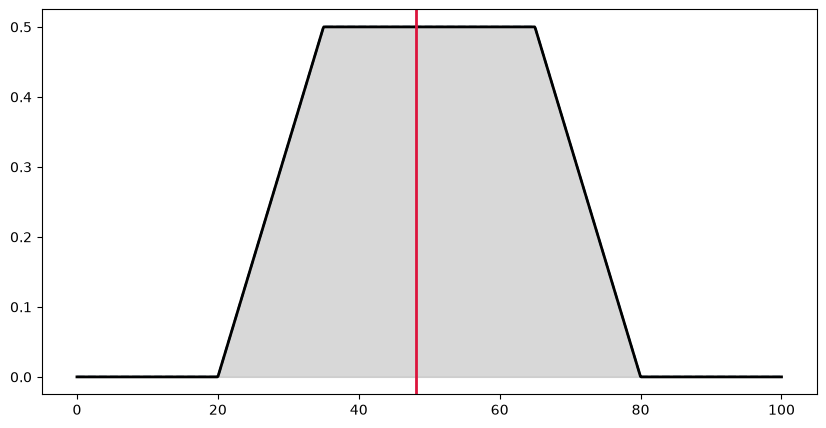

In [88]:
plt.figure(figsize=(10, 5), dpi=100)

# A. Plota as curvas individuais ativadas (opcional, para visualização)
plt.plot(y_universo, ativacao_regra1, 'b--', alpha=0.6, label='Ativação Regra 1')
plt.plot(y_universo, ativacao_regra2, 'g--', alpha=0.6, label='Ativação Regra 2')

# B. Plota a linha contínua da Superfície Agregada (Max-Min de Zadeh)
plt.plot(y_universo, superficie_agregada, 'k-', linewidth=2, label='Superfície Agregada')

# C. Preenche a "Massa da Área", que é o alvo geométrico do centroide
plt.fill_between(y_universo, 0, superficie_agregada, color='gray', alpha=0.3, label='Massa da Área Agregada')

# D. Traça a linha vertical Exata interceptando o eixo-x
plt.axvline(x=y_centroide, color='crimson', linestyle='-', linewidth=2, label=f'Centroide Exato ($y^* = {y_centroide:.1f}$)')

# E. Marca o ponto de "Equilíbrio Geométrico" do centroide
plt.plot(y_centroide, mu_centroide / 2.0, marker='o', markersize=8, markerfacecolor='red', markeredgecolor='black', label='Centro de Gravidade (CoG)')

# F. Adiciona uma caixa de texto visual com seta
plt.annotate(f'Sinal de Saída\n(Centroide = {y_centroide:.1f}%)', 
             xy=(y_centroide, mu_centroide / 2.0), 
             xytext=(y_centroide + 10, mu_centroide / 2.0 + 0.1),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
             fontsize=10, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="yellow", ec="black", lw=1))

plt.title('Representação Gráfica: Centro de Gravidade (CoG) em Lógica Fuzzy', fontsize=12, fontweight='bold')
plt.xlabel('Universo de Discurso (Ex: Nível de Ação do Atuador - %)')
plt.ylabel('Grau de Pertinência (\u03bc)')
plt.xlim(0, 100)
plt.ylim(0, 1.0)
plt.grid(True, linestyle=':', alpha=0.7)

# Move a legenda para fora se ela cobrir a curva
plt.legend(loc='upper left', bbox_to_anchor=(1, 1)) 
plt.tight_layout()
plt.show()